<a href="https://colab.research.google.com/github/MaanyaGupta/CSET343/blob/main/CSET343_Lab_Assignment_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSET343 – AI in Healthcare | Lab Assignment 6
**CNN-based automated diagnosis on Chest X-Ray Images (Normal vs Pneumonia)**



## 0. Setup

In [ ]:
!pip -q install kagglehub scikit-image

In [ ]:
import os, random, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from joblib import Parallel, delayed

from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, classification_report)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IMG_SIZE = 128
print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Task 1: Data Acquisition and Exploration
Dataset: *Chest X-Ray Images (Pneumonia)* by Paul Mooney on Kaggle. It ships as `train/`, `val/`, `test/` folders, each with `NORMAL` and `PNEUMONIA`. The original validation folder has only 16 images, so we **pool all images** and create our own stratified 70/15/15 split in Task 2.

In [ ]:
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Downloaded to:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Downloaded to: /kaggle/input/chest-xray-pneumonia


In [ ]:
# Locate the folder that contains train/val/test (handles nested chest_xray/chest_xray layouts)
root = None
for dp, dn, fn in os.walk(path):
    if {"train", "test"}.issubset(set(dn)):
        root = dp; break
print("Dataset root:", root)

records = []
for split in ["train", "val", "test"]:
    for cls in ["NORMAL", "PNEUMONIA"]:
        d = os.path.join(root, split, cls)
        if not os.path.isdir(d): continue
        for f in os.listdir(d):
            if f.lower().endswith((".jpeg", ".jpg", ".png")):
                records.append((os.path.join(d, f), cls, split))
df = pd.DataFrame(records, columns=["path", "label", "orig_split"])
df["y"] = (df["label"] == "PNEUMONIA").astype(int)   # 1 = Pneumonia (positive class)
print("Total images:", len(df))
df.head()

Dataset root: /kaggle/input/chest-xray-pneumonia/chest_xray
Total images: 5856


,path,label,orig_split,y
0,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,train,0
1,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,train,0
2,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,train,0
3,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,train,0
4,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,train,0


### 1.1 Class balance

label
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64
label
PNEUMONIA    72.97 %
NORMAL       27.03 %
Name: count, dtype: object


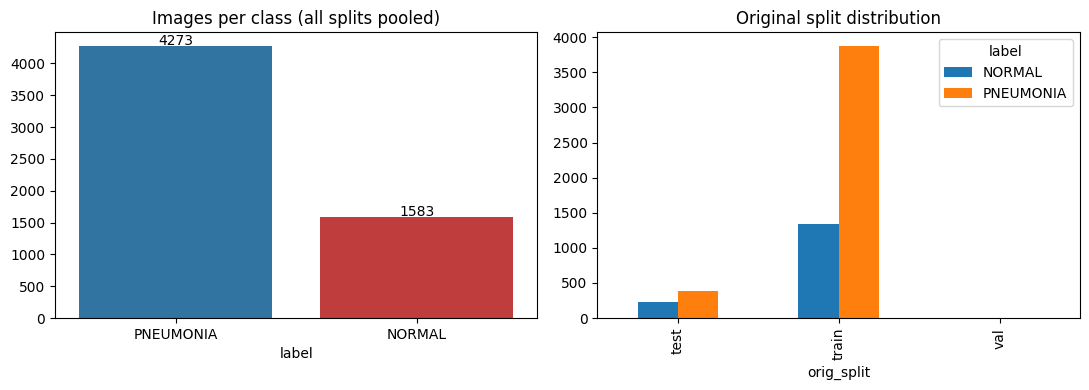

Imbalance ratio (Pneumonia : Normal) = 2.70 : 1


In [ ]:
counts = df["label"].value_counts()
print(counts)
print((counts / len(df) * 100).round(2).astype(str) + " %")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax[0], palette=["tab:blue", "tab:red"])
for i, v in enumerate(counts.values): ax[0].text(i, v + 20, str(v), ha="center")
ax[0].set_title("Images per class (all splits pooled)")
pd.crosstab(df["orig_split"], df["label"]).plot(kind="bar", ax=ax[1])
ax[1].set_title("Original split distribution"); plt.tight_layout(); plt.show()
print("Imbalance ratio (Pneumonia : Normal) = %.2f : 1" % (counts["PNEUMONIA"] / counts["NORMAL"]))

**Observation:** the dataset is imbalanced: Pneumonia images outnumber Normal ones by roughly 3 : 1. Accuracy alone would be misleading (predicting "Pneumonia" for everything already gives ~73 %), so we also report Precision, Recall, F1 and AUROC, and use class weights while training.

### 1.2 Random sample images from each class

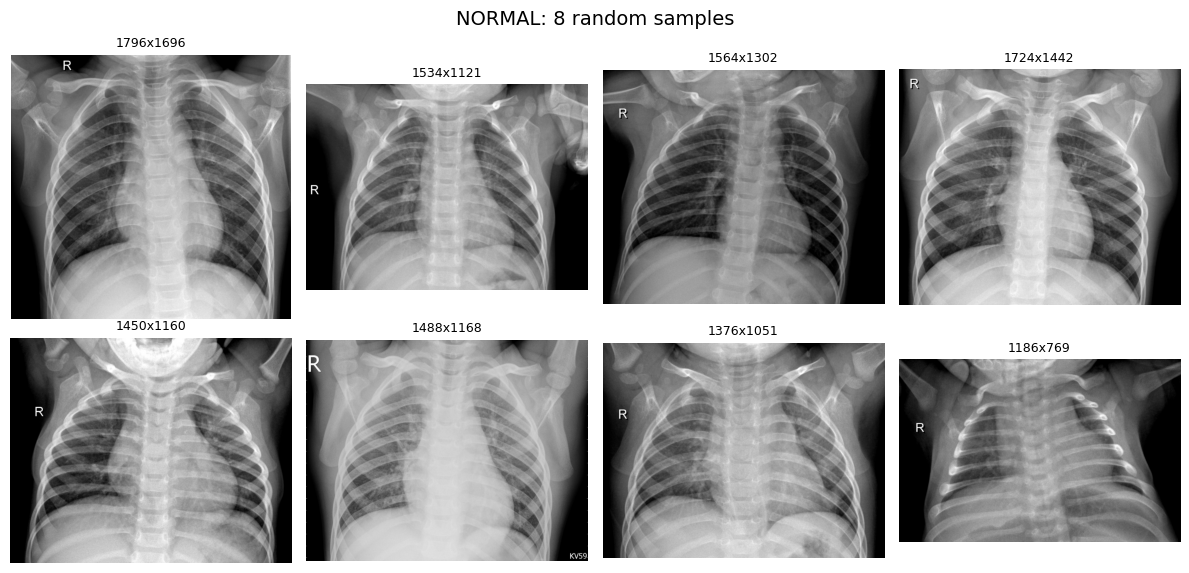

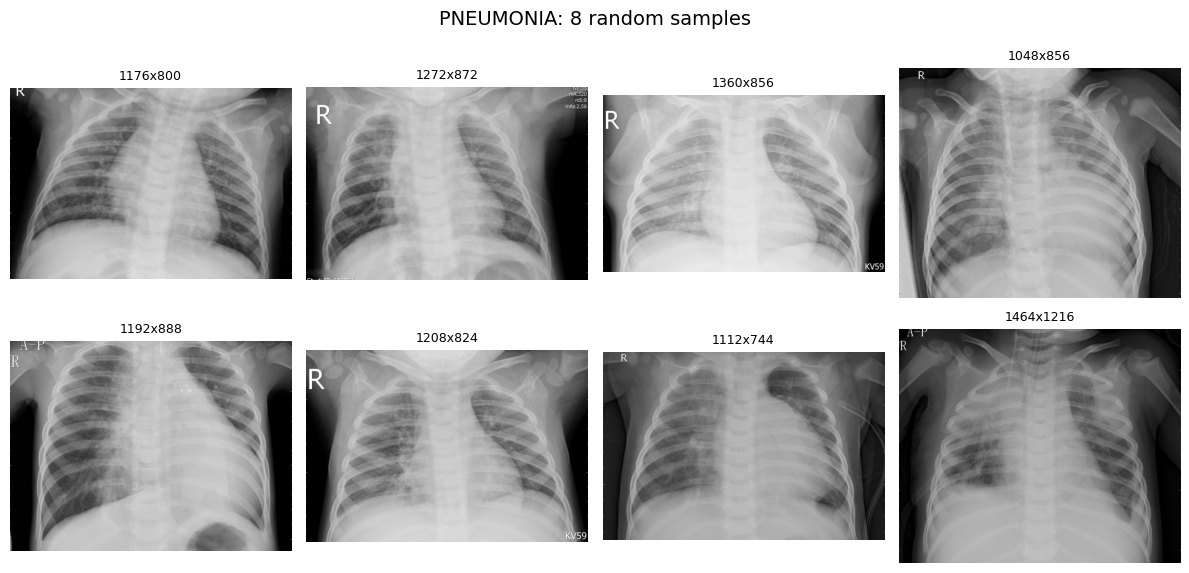

In [ ]:
def show_samples(label, n=8):
    paths = df[df.label == label].sample(n, random_state=SEED)["path"].tolist()
    fig, axes = plt.subplots(2, n // 2, figsize=(3 * n // 2, 6))
    for ax, p in zip(axes.ravel(), paths):
        img = Image.open(p).convert("L")
        ax.imshow(img, cmap="gray"); ax.set_title(f"{img.size[0]}x{img.size[1]}", fontsize=9); ax.axis("off")
    fig.suptitle(f"{label}: {n} random samples", fontsize=14); plt.tight_layout(); plt.show()

show_samples("NORMAL"); show_samples("PNEUMONIA")

In [ ]:
# Image size variability (motivates fixed-size resizing)
sizes = [Image.open(p).size for p in df.sample(300, random_state=SEED)["path"]]
sz = pd.DataFrame(sizes, columns=["w", "h"]); print(sz.describe().loc[["min", "mean", "max"]].round(0))

           w       h
min    462.0   238.0
mean  1308.0   954.0
max   2564.0  2663.0


## Task 2: Data Preprocessing
Steps: load as **grayscale** → resize to **128×128** → scale pixels to [0, 1] → extract **HOG, LBP, GLCM** features → stratified **70/15/15** split.

In [ ]:
def load_img(p):
    img = Image.open(p).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    return np.asarray(img, dtype=np.uint8)

t0 = time.time()
imgs = Parallel(n_jobs=-1)(delayed(load_img)(p) for p in df["path"])
X_img = np.stack(imgs)                      # (N, 128, 128) uint8
y = df["y"].values
print("Image tensor:", X_img.shape, "| time %.1fs" % (time.time() - t0))

Image tensor: (5856, 128, 128) | time 52.0s


### 2.1 Feature extraction
- **HOG** – captures edge/gradient orientation structure (lung borders, opacities).
- **LBP** (uniform, P=8, R=1) – histogram of local micro-texture patterns.
- **GLCM** – second-order texture statistics (contrast, dissimilarity, homogeneity, energy, correlation, ASM) at 2 distances × 4 angles. Image is quantised to 32 grey levels to keep the matrix small.

In [ ]:
LBP_P, LBP_R = 8, 1
GLCM_LEVELS = 32
GLCM_PROPS = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]

def f_hog(img):
    return hog(img, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2),
               block_norm="L2-Hys", feature_vector=True)

def f_lbp(img):
    lbp = local_binary_pattern(img, LBP_P, LBP_R, method="uniform")
    hist, _ = np.histogram(lbp, bins=np.arange(0, LBP_P + 3), range=(0, LBP_P + 2), density=True)
    return hist

def f_glcm(img):
    q = (img // (256 // GLCM_LEVELS)).astype(np.uint8)
    g = graycomatrix(q, distances=[1, 3], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                     levels=GLCM_LEVELS, symmetric=True, normed=True)
    return np.concatenate([graycoprops(g, p).ravel() for p in GLCM_PROPS])

def extract(img):
    return f_hog(img), f_lbp(img), f_glcm(img)

t0 = time.time()
feats = Parallel(n_jobs=-1)(delayed(extract)(im) for im in X_img)
F_hog  = np.stack([f[0] for f in feats])
F_lbp  = np.stack([f[1] for f in feats])
F_glcm = np.stack([f[2] for f in feats])
F_all  = np.hstack([F_hog, F_lbp, F_glcm])
print(f"HOG {F_hog.shape} | LBP {F_lbp.shape} | GLCM {F_glcm.shape} | Combined {F_all.shape}")
print("Extraction time %.1fs" % (time.time() - t0))

HOG (5856, 1764) | LBP (5856, 10) | GLCM (5856, 48) | Combined (5856, 1822)
Extraction time 41.7s


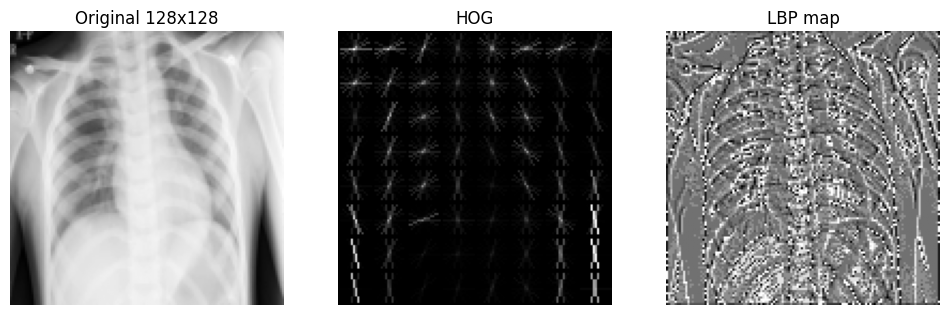

In [ ]:
# Visualise what each descriptor sees
i = np.random.RandomState(1).choice(np.where(y == 1)[0])
_, hog_img = hog(X_img[i], orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), visualize=True)
lbp_img = local_binary_pattern(X_img[i], LBP_P, LBP_R, method="uniform")
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, im, t in zip(ax, [X_img[i], hog_img, lbp_img], ["Original 128x128", "HOG", "LBP map"]):
    a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
plt.show()

### 2.2 Train / Validation / Test split (70 / 15 / 15, stratified)

In [ ]:
idx = np.arange(len(y))
idx_tr, idx_tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.50, stratify=y[idx_tmp], random_state=SEED)

def pack(ix):
    return X_img[ix][..., None].astype("float32") / 255.0, F_all[ix], y[ix]

Xi_tr, Xf_tr, y_tr = pack(idx_tr)
Xi_va, Xf_va, y_va = pack(idx_va)
Xi_te, Xf_te, y_te = pack(idx_te)

# Scale handcrafted features (fit on TRAIN only to avoid leakage)
scaler = StandardScaler().fit(Xf_tr)
Xf_tr_s, Xf_va_s, Xf_te_s = scaler.transform(Xf_tr), scaler.transform(Xf_va), scaler.transform(Xf_te)

for n, yy in [("Train", y_tr), ("Val", y_va), ("Test", y_te)]:
    print(f"{n:5s}: {len(yy):5d} images | Pneumonia {yy.mean()*100:.1f}%")

Train:  4099 images | Pneumonia 73.0%
Val  :   878 images | Pneumonia 73.0%
Test :   879 images | Pneumonia 72.9%


## Task 3: Model Training and Evaluation
### 3.1 Evaluation helper

In [ ]:
results = {}          # name -> metrics dict
probs_store = {}      # name -> (y_prob_test)

def evaluate(name, y_true, y_prob, thr=0.5, store=True):
    y_pred = (y_prob >= thr).astype(int)
    m = dict(Accuracy=accuracy_score(y_true, y_pred),
             Precision=precision_score(y_true, y_pred),
             Recall=recall_score(y_true, y_pred),
             F1=f1_score(y_true, y_pred),
             AUROC=roc_auc_score(y_true, y_prob))
    if store:
        results[name] = m; probs_store[name] = y_prob
    return m, y_pred

def plot_cm(name, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Normal", "Pneumonia"], yticklabels=["Normal", "Pneumonia"])
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion matrix – {name}"); plt.show()
    return cm

### 3.2 Baseline CNN
A compact 3-block CNN (Conv → BatchNorm → ReLU → MaxPool), global average pooling, dense head with dropout, sigmoid output. Trained with binary cross-entropy and **class weights** to counter the 3:1 imbalance.

In [ ]:
def build_cnn(lr=1e-3, dropout=0.4, base_filters=32):
    m = models.Sequential([
        layers.Input((IMG_SIZE, IMG_SIZE, 1)),
        layers.RandomFlip("horizontal"), layers.RandomRotation(0.05), layers.RandomZoom(0.1),
        layers.Conv2D(base_filters, 3, padding="same"), layers.BatchNormalization(), layers.ReLU(), layers.MaxPooling2D(),
        layers.Conv2D(base_filters*2, 3, padding="same"), layers.BatchNormalization(), layers.ReLU(), layers.MaxPooling2D(),
        layers.Conv2D(base_filters*4, 3, padding="same"), layers.BatchNormalization(), layers.ReLU(), layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"), layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer=optimizers.Adam(lr), loss="binary_crossentropy",
              metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return m

cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_tr)
class_weight = {0: cw[0], 1: cw[1]}
print("Class weights:", class_weight)
build_cnn().summary()

Class weights: {0: np.float64(1.8497292418772564), 1: np.float64(0.6852223336676697)}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 1)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,209 (430.50 KB)

 Trainable params: 109,761 (428.75 KB)

 Non-trainable params: 448 (1.75 KB)

### 3.3 Hyperparameter tuning with cross-validation
Stratified **3-fold CV on the training set only** over learning rate × dropout (validation and test data are never touched). Selection metric: mean validation AUROC across folds. (Short 6-epoch runs keep this affordable on a Colab GPU; increase `CV_EPOCHS` for a more careful search.)

In [ ]:
CV_EPOCHS, CV_FOLDS, BATCH = 6, 3, 32
grid = [dict(lr=lr, dropout=dp) for lr in [1e-3, 3e-4] for dp in [0.3, 0.5]]
skf = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)

cv_rows = []
for g in grid:
    aucs, f1s = [], []
    for k, (a, b) in enumerate(skf.split(Xi_tr, y_tr)):
        tf.keras.backend.clear_session()
        m = build_cnn(**g)
        m.fit(Xi_tr[a], y_tr[a], epochs=CV_EPOCHS, batch_size=BATCH, class_weight=class_weight, verbose=0)
        p = m.predict(Xi_tr[b], verbose=0).ravel()
        aucs.append(roc_auc_score(y_tr[b], p)); f1s.append(f1_score(y_tr[b], p >= 0.5))
    cv_rows.append({**g, "CV_AUROC": np.mean(aucs), "CV_AUROC_std": np.std(aucs), "CV_F1": np.mean(f1s)})
    print(g, "-> AUROC %.4f ± %.4f | F1 %.4f" % (np.mean(aucs), np.std(aucs), np.mean(f1s)))

cv_df = pd.DataFrame(cv_rows).sort_values("CV_AUROC", ascending=False).reset_index(drop=True)
display(cv_df)
best_cnn_params = {k: cv_df.loc[0, k] for k in ["lr", "dropout"]}
print("Best CNN hyperparameters:", best_cnn_params)

{'lr': 0.001, 'dropout': 0.3} -> AUROC 0.8309 ± 0.0315 | F1 0.8467
{'lr': 0.001, 'dropout': 0.5} -> AUROC 0.8936 ± 0.0328 | F1 0.8735
{'lr': 0.0003, 'dropout': 0.3} -> AUROC 0.8853 ± 0.0540 | F1 0.8586
{'lr': 0.0003, 'dropout': 0.5} -> AUROC 0.9081 ± 0.0295 | F1 0.8670


,lr,dropout,CV_AUROC,CV_AUROC_std,CV_F1
0,0.0003,0.5,0.908084,0.029485,0.866982
1,0.0010,0.5,0.893571,0.032833,0.873473
2,0.0003,0.3,0.885348,0.053962,0.858596
3,0.0010,0.3,0.830908,0.031533,0.846716


Best CNN hyperparameters: {'lr': np.float64(0.0003), 'dropout': np.float64(0.5)}


### 3.4 Train the final CNN with the best hyperparameters (early stopping on the validation set)

Epoch 1/30
129/129 - 9s - 72ms/step - accuracy: 0.7960 - auc: 0.8880 - loss: 0.4217 - val_accuracy: 0.7301 - val_auc: 0.5260 - val_loss: 0.8829 - learning_rate: 3.0000e-04
Epoch 2/30
129/129 - 6s - 45ms/step - accuracy: 0.8561 - auc: 0.9251 - loss: 0.3391 - val_accuracy: 0.7301 - val_auc: 0.5287 - val_loss: 1.3413 - learning_rate: 3.0000e-04
Epoch 3/30
129/129 - 6s - 45ms/step - accuracy: 0.8626 - auc: 0.9338 - loss: 0.3218 - val_accuracy: 0.7301 - val_auc: 0.7840 - val_loss: 1.3266 - learning_rate: 3.0000e-04
Epoch 4/30
129/129 - 6s - 45ms/step - accuracy: 0.8739 - auc: 0.9419 - loss: 0.3005 - val_accuracy: 0.7779 - val_auc: 0.9521 - val_loss: 0.4040 - learning_rate: 3.0000e-04
Epoch 5/30
129/129 - 6s - 44ms/step - accuracy: 0.8761 - auc: 0.9432 - loss: 0.2986 - val_accuracy: 0.8998 - val_auc: 0.9608 - val_loss: 0.2425 - learning_rate: 3.0000e-04
Epoch 6/30
129/129 - 6s - 44ms/step - accuracy: 0.8807 - auc: 0.9508 - loss: 0.2804 - val_accuracy: 0.8223 - val_auc: 0.9702 - val_loss: 0.3

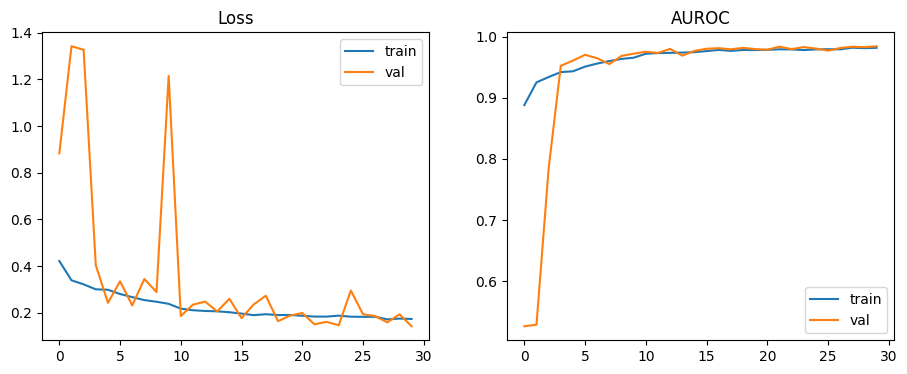

In [ ]:
tf.keras.backend.clear_session()
cnn = build_cnn(**best_cnn_params)
cbs = [callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True),
       callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1)]
hist = cnn.fit(Xi_tr, y_tr, validation_data=(Xi_va, y_va), epochs=30, batch_size=BATCH,
               class_weight=class_weight, callbacks=cbs, verbose=2)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist.history["auc"], label="train"); ax[1].plot(hist.history["val_auc"], label="val"); ax[1].set_title("AUROC"); ax[1].legend()
plt.show()

### 3.5 CNN evaluation on the held-out test set

Accuracy     0.9488
Precision    0.9715
Recall       0.9579
F1           0.9647
AUROC        0.9826
dtype: float64
              precision    recall  f1-score   support

      Normal     0.8907    0.9244    0.9072       238
   Pneumonia     0.9715    0.9579    0.9647       641

    accuracy                         0.9488       879
   macro avg     0.9311    0.9411    0.9359       879
weighted avg     0.9496    0.9488    0.9491       879



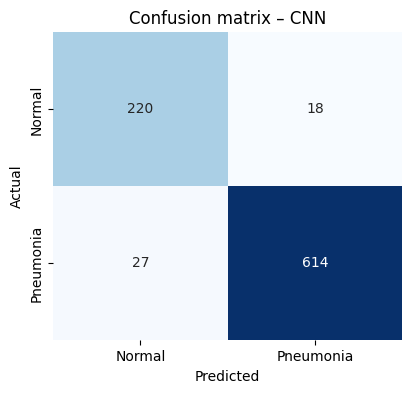

TN=220  FP=18  FN=27  TP=614


In [ ]:
p_cnn = cnn.predict(Xi_te, verbose=0).ravel()
m, pred_cnn = evaluate("CNN (baseline)", y_te, p_cnn)
print(pd.Series(m).round(4))
print(classification_report(y_te, pred_cnn, target_names=["Normal", "Pneumonia"], digits=4))
cm_cnn = plot_cm("CNN", y_te, pred_cnn)
tn, fp, fn, tp = cm_cnn.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

### 3.6 Misclassification analysis

False positives: 18 | False negatives: 27


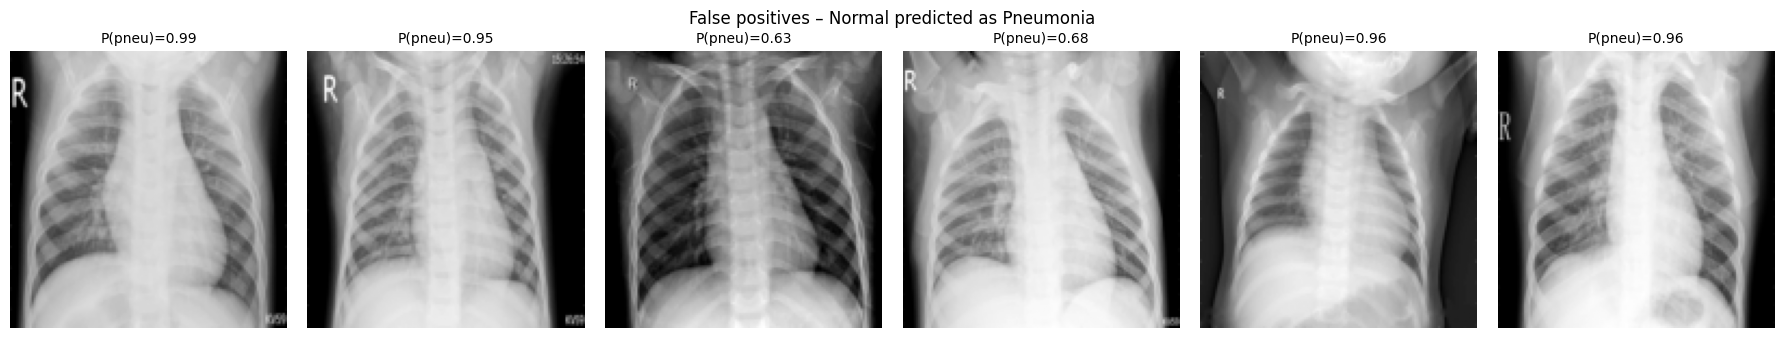

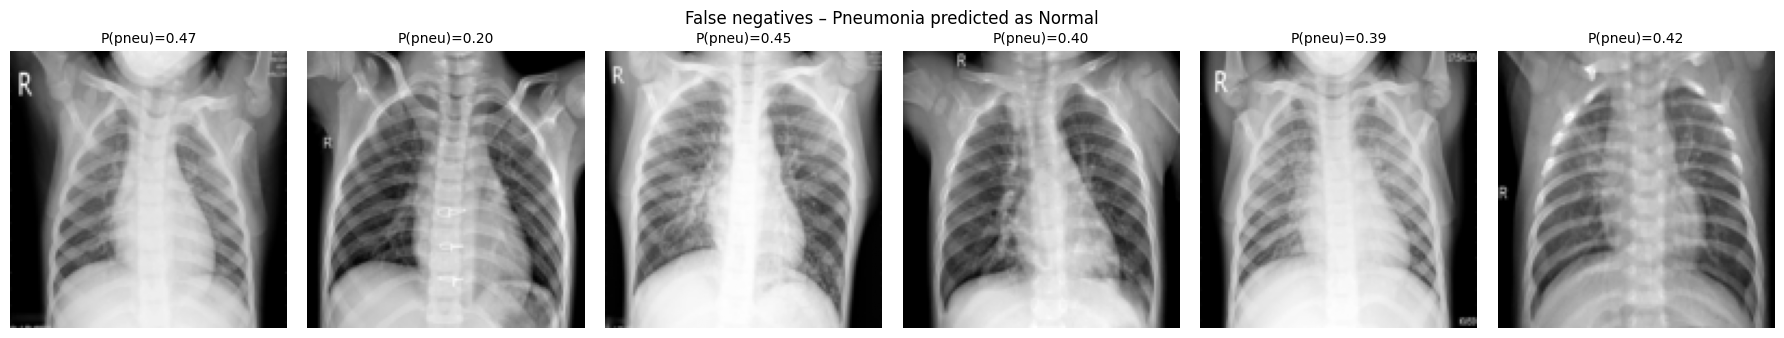

In [ ]:
wrong = np.where(pred_cnn != y_te)[0]
fp_idx = [i for i in wrong if y_te[i] == 0]    # Normal predicted as Pneumonia
fn_idx = [i for i in wrong if y_te[i] == 1]    # Pneumonia missed
print(f"False positives: {len(fp_idx)} | False negatives: {len(fn_idx)}")

def show_wrong(ix, title, n=6):
    ix = ix[:n]
    if not ix: print("None"); return
    fig, axes = plt.subplots(1, len(ix), figsize=(3 * len(ix), 3.4))
    axes = np.atleast_1d(axes)
    for a, i in zip(axes, ix):
        a.imshow(Xi_te[i, ..., 0], cmap="gray"); a.set_title(f"P(pneu)={p_cnn[i]:.2f}", fontsize=10); a.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_wrong(fp_idx, "False positives – Normal predicted as Pneumonia")
show_wrong(fn_idx, "False negatives – Pneumonia predicted as Normal")

**Why the CNN misclassifies (check these against the images above):**

- **False positives (Normal → Pneumonia):** the model is trained with class weights and the Pneumonia class is the majority, so it leans towards flagging suspicious images. Normal scans with rotated posture, over/under-exposure, medical devices/leads, prominent vascular markings or heart shadow, or low contrast can look like diffuse opacity at 128×128.
- **False negatives (Pneumonia → Normal):** mild or early pneumonia with faint, small or unilateral infiltrates. Downsampling to 128×128 blurs these subtle textures. Clinically, **false negatives are the costlier error** (a missed diagnosis), so recall for the Pneumonia class matters more than raw accuracy.
- **Dataset factors:** the images come from paediatric patients at a single centre, with varying acquisition settings; bacterial vs viral pneumonia look different but share one label; some labels may be noisy.
- **Mitigations:** higher resolution (224×224), transfer learning (e.g. DenseNet121 / ResNet50), stronger augmentation, threshold tuning on the validation set to trade precision for recall, and Grad-CAM to verify the model looks at lung regions.

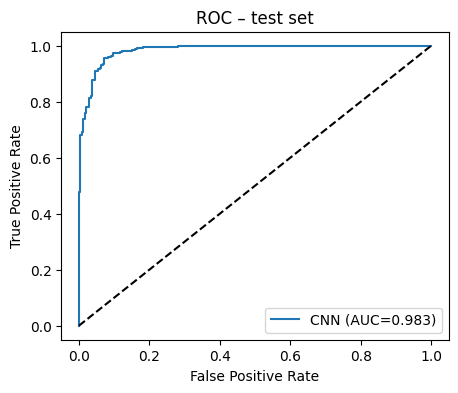

In [ ]:
# Grad-CAM-free sanity check: ROC curve of the CNN on the test set
fpr, tpr, _ = roc_curve(y_te, p_cnn)
plt.figure(figsize=(5, 4)); plt.plot(fpr, tpr, label=f"CNN (AUC={results['CNN (baseline)']['AUROC']:.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.legend(); plt.title("ROC – test set"); plt.show()

### 3.7 Classifiers on handcrafted features (HOG + LBP + GLCM)
To compare the CNN with classical baselines, we train Logistic Regression, SVM (RBF) and Random Forest on the scaled feature vectors. Hyperparameters are tuned by **5-fold stratified cross-validation** (`GridSearchCV`, scoring = AUROC) on the training set only.

In [ ]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
searches = {
    "Logistic Regression": GridSearchCV(LogisticRegression(max_iter=3000, class_weight="balanced"),
                                        {"C": [0.001, 0.01, 0.1, 1]}, cv=cv5, scoring="roc_auc", n_jobs=-1),
    "SVM (RBF)": GridSearchCV(SVC(probability=True, class_weight="balanced", random_state=SEED),
                              {"C": [1, 10], "gamma": ["scale", 1e-4]}, cv=cv5, scoring="roc_auc", n_jobs=-1),
    "Random Forest": GridSearchCV(RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
                                  {"n_estimators": [200, 400], "max_depth": [None, 20]}, cv=cv5, scoring="roc_auc", n_jobs=1),
}
fitted = {}
for name, gs in searches.items():
    t0 = time.time(); gs.fit(Xf_tr_s, y_tr); fitted[name] = gs
    print(f"{name:20s} best={gs.best_params_} | CV AUROC={gs.best_score_:.4f} | {time.time()-t0:.0f}s")
    evaluate(name, y_te, gs.predict_proba(Xf_te_s)[:, 1])

Logistic Regression  best={'C': 0.01} | CV AUROC=0.9897 | 12s
SVM (RBF)            best={'C': 1, 'gamma': 0.0001} | CV AUROC=0.9895 | 378s
Random Forest        best={'max_depth': 20, 'n_estimators': 400} | CV AUROC=0.9829 | 718s


In [ ]:
# Which handcrafted descriptor carries the signal? (Random Forest, one descriptor at a time)
blocks = {"HOG": slice(0, F_hog.shape[1]),
          "LBP": slice(F_hog.shape[1], F_hog.shape[1] + F_lbp.shape[1]),
          "GLCM": slice(F_hog.shape[1] + F_lbp.shape[1], F_all.shape[1])}
rows = []
for k, sl in blocks.items():
    rf = RandomForestClassifier(300, class_weight="balanced", random_state=SEED, n_jobs=-1).fit(Xf_tr_s[:, sl], y_tr)
    pr = rf.predict_proba(Xf_te_s[:, sl])[:, 1]
    rows.append({"Features": k, "Dim": Xf_tr_s[:, sl].shape[1], "AUROC": roc_auc_score(y_te, pr),
                 "F1": f1_score(y_te, pr >= 0.5), "Accuracy": accuracy_score(y_te, pr >= 0.5)})
display(pd.DataFrame(rows).round(4))

,Features,Dim,AUROC,F1,Accuracy
0,HOG,1764,0.9813,0.9626,0.9443
1,LBP,10,0.9345,0.9154,0.8760
2,GLCM,48,0.9529,0.9334,0.9022


### 3.8 Hybrid model: CNN + handcrafted features (extra)

In [ ]:
def build_hybrid(lr=1e-3, dropout=0.4, base_filters=32):
    img_in = layers.Input((IMG_SIZE, IMG_SIZE, 1)); f_in = layers.Input((Xf_tr_s.shape[1],))
    x = layers.RandomFlip("horizontal")(img_in)
    for mult in [1, 2, 4]:
        x = layers.Conv2D(base_filters*mult, 3, padding="same")(x); x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x); x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    f = layers.Dense(64, activation="relu")(f_in); f = layers.Dropout(dropout)(f)
    z = layers.Concatenate()([x, f]); z = layers.Dense(128, activation="relu")(z); z = layers.Dropout(dropout)(z)
    out = layers.Dense(1, activation="sigmoid")(z)
    m = models.Model([img_in, f_in], out)
    m.compile(optimizers.Adam(lr), "binary_crossentropy", metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return m

tf.keras.backend.clear_session()
hyb = build_hybrid(**best_cnn_params)
hyb.fit([Xi_tr, Xf_tr_s], y_tr, validation_data=([Xi_va, Xf_va_s], y_va), epochs=30, batch_size=BATCH,
        class_weight=class_weight, callbacks=[callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True)], verbose=0)
evaluate("Hybrid CNN + features", y_te, hyb.predict([Xi_te, Xf_te_s], verbose=0).ravel());

### 3.9 Model comparison and best performer

,Accuracy,Precision,Recall,F1,AUROC
Hybrid CNN + features,0.953400,0.980800,0.954800,0.967600,0.989500
Logistic Regression,0.953400,0.974700,0.961000,0.967800,0.987400
SVM (RBF),0.959000,0.973400,0.970400,0.971900,0.985600
CNN (baseline),0.948800,0.971500,0.957900,0.964700,0.982600
Random Forest,0.951100,0.957200,0.976600,0.966800,0.979000


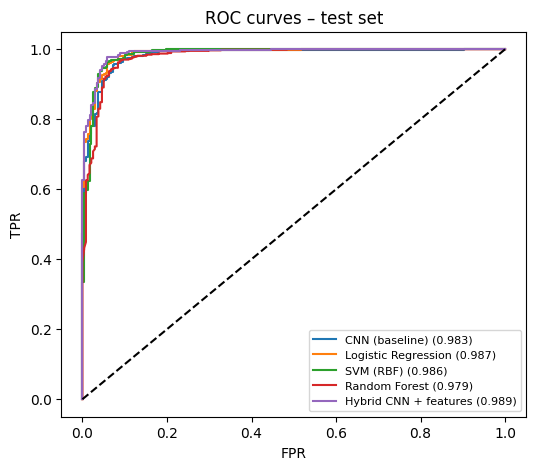

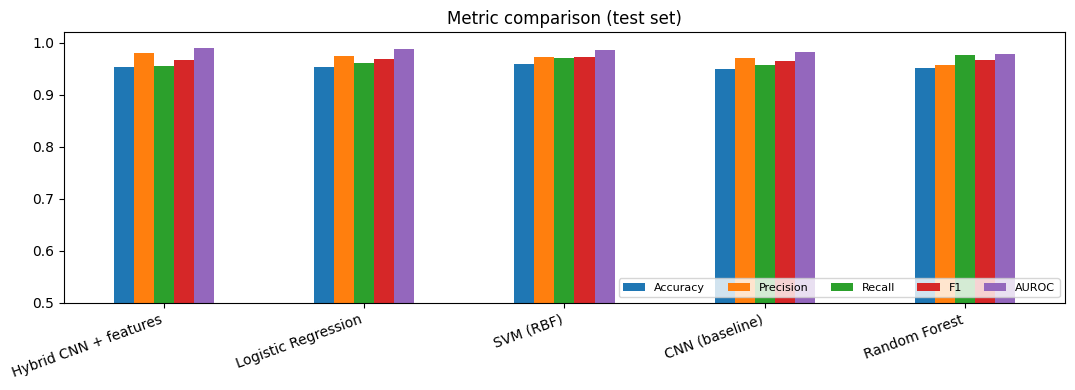

Best model by AUROC: Hybrid CNN + features  ->  {'Accuracy': 0.9534, 'Precision': 0.9808, 'Recall': 0.9548, 'F1': 0.9676, 'AUROC': 0.9895}


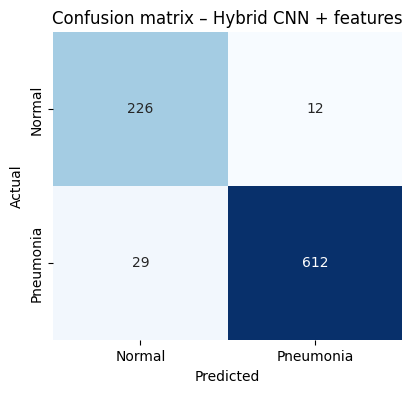

In [ ]:
res = pd.DataFrame(results).T.round(4).sort_values("AUROC", ascending=False)
display(res.style.background_gradient(cmap="Greens", axis=0))

plt.figure(figsize=(6, 5))
for n, pr in probs_store.items():
    f, t, _ = roc_curve(y_te, pr); plt.plot(f, t, label=f"{n} ({results[n]['AUROC']:.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC curves – test set"); plt.legend(fontsize=8); plt.show()

res.plot(kind="bar", figsize=(11, 4)); plt.ylim(0.5, 1.02); plt.title("Metric comparison (test set)")
plt.xticks(rotation=20, ha="right"); plt.legend(loc="lower right", ncol=5, fontsize=8); plt.tight_layout(); plt.show()

best = res.index[0]
print(f"Best model by AUROC: {best}  ->  {res.loc[best].to_dict()}")
_, pred_best = evaluate(best, y_te, probs_store[best], store=False)
plot_cm(best, y_te, pred_best);

### Conclusions
1. **Class imbalance** (~3:1 Pneumonia:Normal) means accuracy alone is misleading; Recall, F1 and AUROC are reported, and class weights are used in training.
2. **CNN vs handcrafted features:** the CNN learns lung-specific texture and shape directly from pixels and normally outperforms classical classifiers on HOG/LBP/GLCM vectors. Among the descriptors, HOG is typically the most informative, while LBP and GLCM add complementary texture cues (see the descriptor ablation in 3.7).
3. **Best performer:** see the table in 3.9. The model with the highest AUROC (with a strong Recall) is selected; for a screening use case a high Recall for Pneumonia is preferred because missed diagnoses are costlier than false alarms.
4. **Limitations / next steps:** 128×128 input loses fine detail; single-centre paediatric data limits generalisation. Transfer learning, higher resolution, threshold tuning on the validation set, Grad-CAM explainability and external validation would be the next steps.

*(Exact numbers vary slightly between runs and GPUs. Fill in your final figures in the report after running all cells.)*